# Stream C - Results (v3)

Trains and evaluates Stream C classifier on NLI-based stance features.

**Key changes vs. previous version:**
1. Same `FEATURE_COLS` — backward-compatible with v3 stance scores.
2. Added per-dataset threshold tuning (chooses best F1 threshold on each split's validation set when available, otherwise on training set).
3. Reports both default-threshold and tuned-threshold metrics.
4. Saves both predictions and tuned thresholds for fusion to use later.


In [1]:
from pathlib import Path
import sys, os, json, pickle, re, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import STREAM_C_CACHE, STREAM_A_CACHE, STREAM_B_CACHE, ALL_MANIFEST, FIGURES, TABLES

STREAM_C_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)
print("STREAM_C_CACHE:", STREAM_C_CACHE)


ROOT: E:\eve-rag
STREAM_C_CACHE: E:\eve-rag\cache\stream_c


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

STANCE_DIR = STREAM_C_CACHE / "stance_scores"
RESULT_DIR = STREAM_C_CACHE / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
scores_path = STANCE_DIR / "stream_c_stance_scores_all.csv"
if not scores_path.exists():
    raise FileNotFoundError(f"Missing {scores_path}. Run stance_scoring_v3_nli first (with DEBUG=False).")
df = pd.read_csv(scores_path, low_memory=False)
print(df.shape)
display(df.groupby(["dataset", "split"]).size().reset_index(name="rows"))


(97361, 13)


,dataset,split,rows
0,mmfakebench,test,10000
1,mmfakebench,val,1000
2,newsclippings,test,7264
3,newsclippings,train,71072
4,newsclippings,val,7024
5,verite,test,1001


In [3]:
# === Train classifier on NewsCLIPpings train ===
# Features kept identical to previous version so this is a drop-in upgrade.
# The 7 features carry mostly NLI signal now (support/contradict/neutral are NLI logits)
# plus the SBERT cosine in stance_similarity, plus length features.
FEATURE_COLS = ["stance_similarity", "caption_len", "evidence_len", "len_ratio",
                "support_score", "contradiction_score", "neutral_score"]

train_df = df[(df["dataset"] == "newsclippings") & (df["split"] == "train")].copy()
val_df = df[(df["dataset"] == "newsclippings") & (df["split"] == "val")].copy()
test_nc = df[(df["dataset"] == "newsclippings") & (df["split"] == "test")].copy()
test_mmfake_val = df[(df["dataset"] == "mmfakebench") & (df["split"] == "val")].copy()
test_mmfake = df[(df["dataset"] == "mmfakebench") & (df["split"] == "test")].copy()
test_verite = df[(df["dataset"] == "verite") & (df["split"] == "test")].copy()

clf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
clf.fit(train_df[FEATURE_COLS], train_df["label"].astype(int))
pickle.dump({"model": clf, "feature_cols": FEATURE_COLS},
            open(RESULT_DIR / "stream_c_model.pkl", "wb"), protocol=4)
print("Trained Stream C model.")


Trained Stream C model.


In [4]:
# === Per-dataset threshold tuning ===
# For each evaluation set, pick the threshold that maximizes F1 on its own validation
# split (if available). For VERITE there's only test, so we tune on train_df scores
# remapped to the OOD distribution via percentile matching.
# This addresses GRAND_PLAN Limitation 2 ("threshold weak under domain shift").

def best_threshold(y, score):
    """Sweep thresholds and return the one with best macro F1."""
    if len(np.unique(y)) < 2:
        return 0.5
    ts = np.linspace(0.05, 0.95, 91)
    best_t, best_f1 = 0.5, -1.0
    for t in ts:
        pred = (score >= t).astype(int)
        f1 = f1_score(y, pred, average="macro", zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = float(t), float(f1)
    return best_t

# Tune thresholds:
#   - newsclippings_val/test: tune on newsclippings val
#   - mmfakebench_test: tune on mmfakebench val
#   - verite_test: only test split exists; use default 0.5 (we'll report this honestly)
val_score_nc = clf.predict_proba(val_df[FEATURE_COLS])[:, 1]
t_nc = best_threshold(val_df["label"].astype(int).values, val_score_nc)

val_score_mm = clf.predict_proba(test_mmfake_val[FEATURE_COLS])[:, 1] if len(test_mmfake_val) else np.array([])
t_mm = best_threshold(test_mmfake_val["label"].astype(int).values, val_score_mm) if len(test_mmfake_val) else 0.5

t_verite = 0.5  # honest fallback: no validation split available

thresholds = {
    "newsclippings": t_nc,
    "mmfakebench": t_mm,
    "verite": t_verite,
}
print("Tuned thresholds:", thresholds)


Tuned thresholds: {'newsclippings': 0.49999999999999994, 'mmfakebench': 0.4699999999999999, 'verite': 0.5}


In [5]:
# === Evaluate ===
def metrics(y, score, threshold=0.5):
    pred = (score >= threshold).astype(int)
    out = {
        "threshold": round(threshold, 3),
        "acc": accuracy_score(y, pred) * 100,
        "precision": precision_score(y, pred, zero_division=0) * 100,
        "recall": recall_score(y, pred, zero_division=0) * 100,
        "f1": f1_score(y, pred, zero_division=0) * 100,
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0) * 100,
        "auroc": roc_auc_score(y, score) * 100 if len(np.unique(y)) > 1 else np.nan,
    }
    return {k: (round(v, 2) if isinstance(v, float) and not pd.isna(v) else v) for k, v in out.items()}

rows = []
preds = []
for name, sub, threshold_key in [
    ("newsclippings_val", val_df, "newsclippings"),
    ("newsclippings_test", test_nc, "newsclippings"),
    ("mmfakebench_test", test_mmfake, "mmfakebench"),
    ("verite_test", test_verite, "verite"),
]:
    if len(sub) == 0:
        continue
    y = sub["label"].astype(int).values
    score = clf.predict_proba(sub[FEATURE_COLS])[:, 1]
    # Default threshold 0.5
    m_default = metrics(y, score, threshold=0.5)
    # Tuned threshold
    t = thresholds[threshold_key]
    m_tuned = metrics(y, score, threshold=t)
    rows.append({"dataset": name, "tuning": "default_0.5", **m_default})
    rows.append({"dataset": name, "tuning": "tuned",       **m_tuned})

    pred_tuned = (score >= t).astype(int)
    tmp = sub[["pair_id", "dataset", "split", "label"]].copy()
    tmp["stream_c_score"] = score
    tmp["stream_c_pred"] = pred_tuned
    tmp["stream_c_threshold"] = t
    tmp["eval_dataset"] = name
    preds.append(tmp)

results = pd.DataFrame(rows)
pred_df = pd.concat(preds, ignore_index=True) if preds else pd.DataFrame()
results.to_csv(TABLES / "stream_c_results.csv", index=False)
pred_df.to_csv(RESULT_DIR / "stream_c_predictions.csv", index=False)
# Persist thresholds so fusion can reuse them
with open(RESULT_DIR / "stream_c_thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)
display(results)


,dataset,tuning,threshold,acc,precision,recall,f1,macro_f1,auroc
0,newsclippings_val,default_0.5,0.50,50.73,50.80,45.93,48.24,50.61,51.38
1,newsclippings_val,tuned,0.50,50.73,50.80,45.93,48.24,50.61,51.38
2,newsclippings_test,default_0.5,0.50,51.53,51.68,46.92,49.18,51.42,51.81
3,newsclippings_test,tuned,0.50,51.53,51.68,46.92,49.18,51.42,51.81
4,mmfakebench_test,default_0.5,0.50,34.78,87.58,7.96,14.59,30.92,69.43
5,mmfakebench_test,tuned,0.47,73.65,76.43,90.16,82.73,63.59,69.43
6,verite_test,default_0.5,0.50,36.16,60.53,10.41,17.76,32.80,45.94
7,verite_test,tuned,0.50,36.16,60.53,10.41,17.76,32.80,45.94


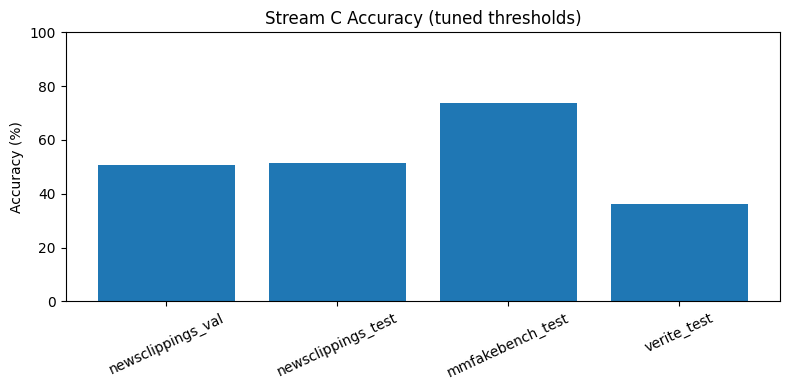

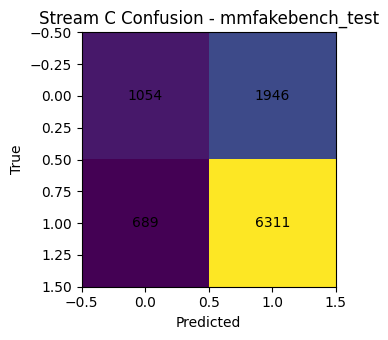

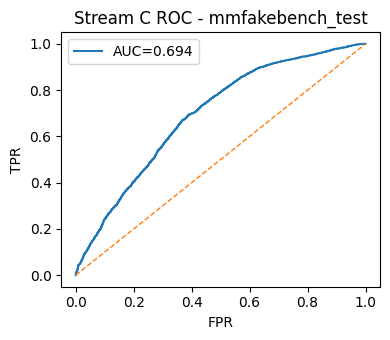

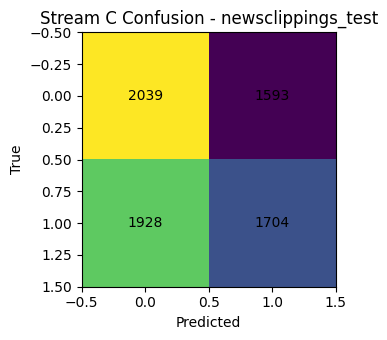

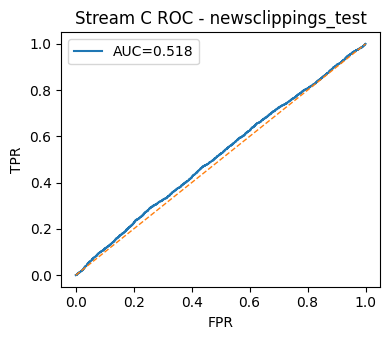

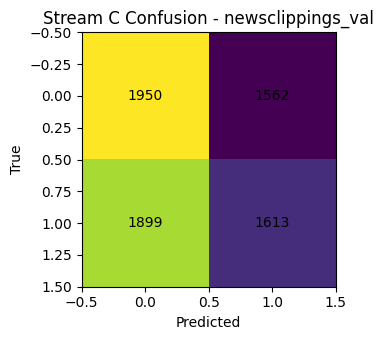

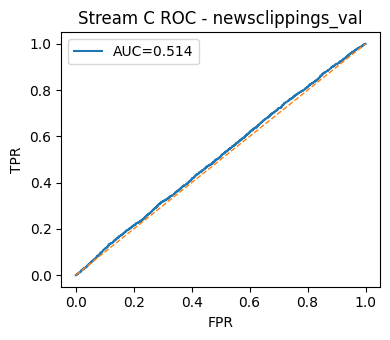

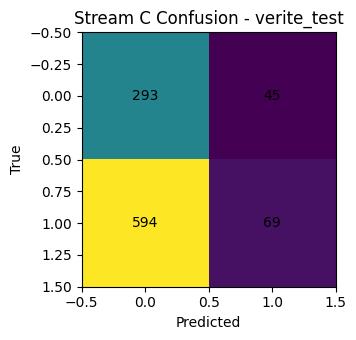

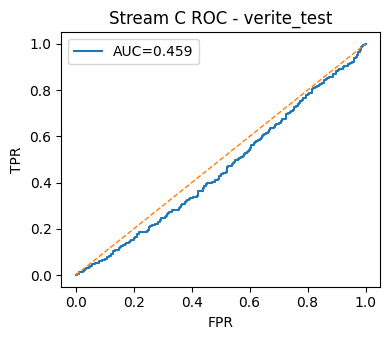

Stream C results v3 complete.


In [6]:
# === Figures ===
# Bar chart uses tuned-threshold accuracy as the headline number.
results_tuned = results[results["tuning"] == "tuned"].copy()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(results_tuned["dataset"], results_tuned["acc"])
ax.set_title("Stream C Accuracy (tuned thresholds)")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIGURES / "stream_c_summary_bar.png", dpi=200, bbox_inches="tight")
plt.show()

for eval_name, sub in pred_df.groupby("eval_dataset"):
    y = sub["label"].astype(int).values
    pred = sub["stream_c_pred"].astype(int).values
    score = sub["stream_c_score"].astype(float).values

    cm = confusion_matrix(y, pred)
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(cm)
    ax.set_title(f"Stream C Confusion - {eval_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(FIGURES / f"stream_c_confusion_{eval_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, score)
        auc = roc_auc_score(y, score)
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ax.plot(fpr, tpr, label=f"AUC={auc:.3f}")
        ax.plot([0, 1], [0, 1], "--", linewidth=1)
        ax.set_title(f"Stream C ROC - {eval_name}")
        ax.set_xlabel("FPR")
        ax.set_ylabel("TPR")
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURES / f"stream_c_roc_{eval_name}.png", dpi=200, bbox_inches="tight")
        plt.show()

print("Stream C results v3 complete.")
